In [42]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [17]:
X,y =  load_breast_cancer(return_X_y=True,as_frame=True)

In [21]:
X_train,X_test,y_train,y_test = train_test_split(
	X,y,test_size=0.2,random_state=42
)

In [22]:
std = StandardScaler()

X_train = std.fit_transform(X_train)
X_test = std.transform(X_test)

In [49]:
knn = KNeighborsClassifier(n_neighbors=9)

In [50]:
knn.fit(X_train,y_train)

KNeighborsClassifier(n_neighbors=9)

In [51]:
y_pred = knn.predict(X_test)
print('accuracy score: ',accuracy_score(y_test,y_pred))

accuracy score:  0.9649122807017544


## Selecting Value of K using Cross Validation Score

In [43]:
accuracy_scores = []


for i in range(1,16):
	knn = KNeighborsClassifier(n_neighbors=i)
	scores = cross_val_score(
		estimator=knn,
		X=X_train,
		y=y_train,
		cv=5,
		scoring='accuracy'
	)
	accuracy_scores.append(scores.mean())

In [32]:
import matplotlib.pyplot as plt

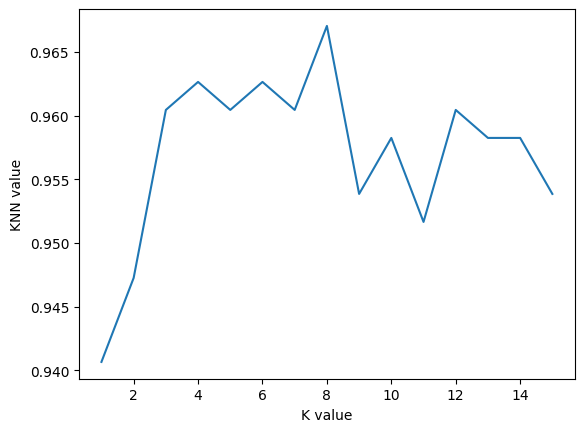

In [44]:
numbers = list(range(1,16))
plt.plot(numbers,accuracy_scores)
plt.xlabel('K value')
plt.ylabel('KNN value')
plt.show()